<a href="https://colab.research.google.com/github/afrateitba/TP-PSI-G8/blob/main/02_mapas_cololr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import os

ROOT = Path('/content/drive/MyDrive/TP-PSI-G8-main')

assert (ROOT / 'src').is_dir(), (
    'No encuentro la carpeta src. Revisá dónde guardaste el proyecto.'
)

os.chdir(ROOT)

print('Carpeta de trabajo:', Path.cwd())

Carpeta de trabajo: /content/drive/MyDrive/TP-PSI-G8-main


In [ ]:
%pip install -q -r requirements.txt

In [ ]:
import sys
from pathlib import Path

In [ ]:
from src.data import dev_ids, load_split

ids = dev_ids()
split = load_split().set_index("image")

print(len(ids), "imágenes de desarrollo")

30 imágenes de desarrollo


In [ ]:
# Nos ubicamos en la carpeta del proyecto
%cd /content/drive/MyDrive/TP-PSI-G8-main

# Descargamos y descomprimimos la base de imágenes
!python scripts/download_data.py

/content
Descarga completa.


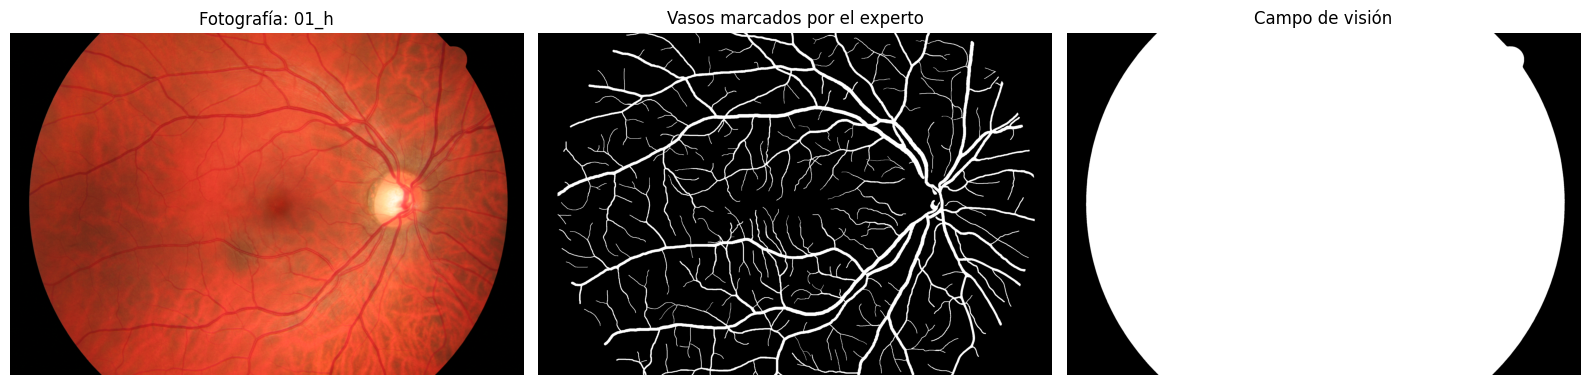

In [ ]:
import matplotlib.pyplot as plt
from src.data import load_image, load_vessels, load_fov

# Elegimos la primera imagen del conjunto de desarrollo
image_id = ids[0]

# Cargamos la fotografía y las referencias
rgb = load_image(image_id)
vasos = load_vessels(image_id)
campo = load_fov(image_id)

# Mostramos las tres imágenes
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(rgb)
ax[0].set_title(f"Fotografía: {image_id}")

ax[1].imshow(vasos, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Vasos marcados por el experto")

ax[2].imshow(campo, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Campo de visión")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

En la imagen analizada, el canal verde presenta visualmente una mejor diferenciación entre los vasos y el fondo que los canales rojo y azul. También se observan variaciones de iluminación que podrían dificultar una segmentación directa por intensidad. Esta observación es exploratoria: la selección del mapa se realizará mediante una comparación cuantitativa en el conjunto de desarrollo.

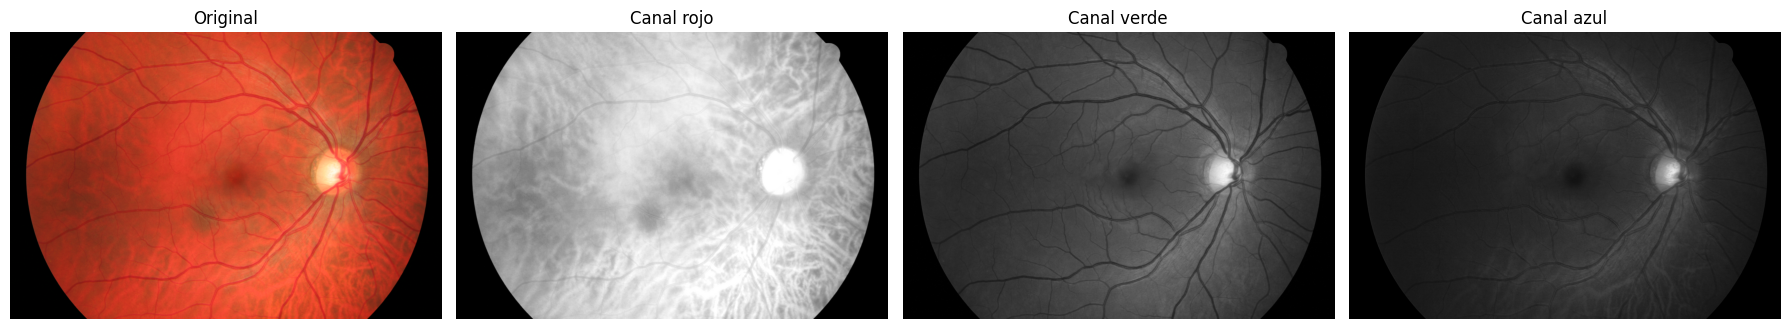

In [ ]:
# Cada canal contiene la intensidad de un color
rojo = rgb[:, :, 0]
verde = rgb[:, :, 1]
azul = rgb[:, :, 2]

fig, ax = plt.subplots(1, 4, figsize=(18, 5))

ax[0].imshow(rgb)
ax[0].set_title("Original")

for a, canal, nombre in zip(
    ax[1:],
    [rojo, verde, azul],
    ["Canal rojo", "Canal verde", "Canal azul"]
):
    a.imshow(canal, cmap="gray", vmin=0, vmax=255)
    a.set_title(nombre)

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

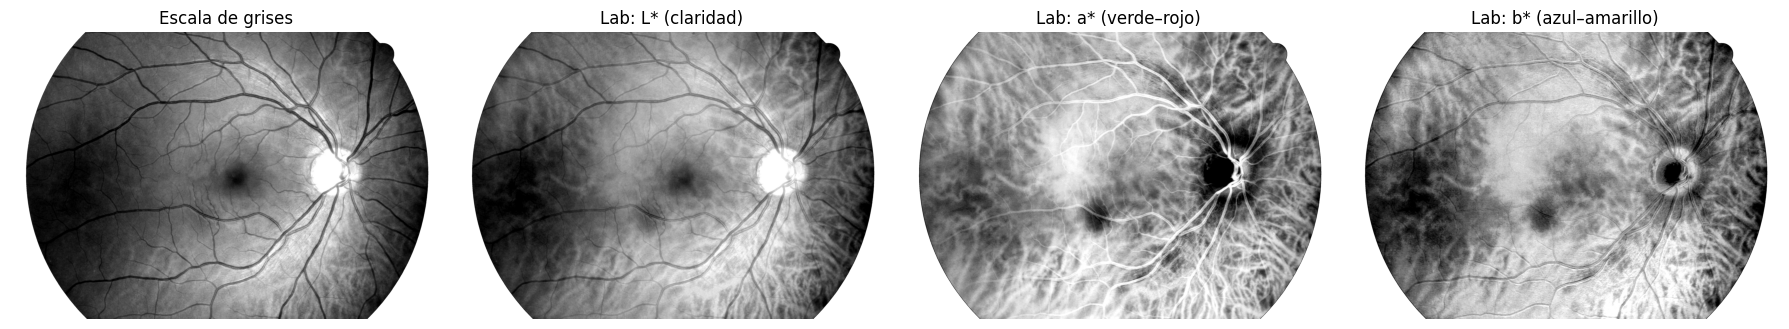

In [ ]:
import numpy as np
from skimage.color import rgb2gray, rgb2lab

# Convertimos la fotografía a valores entre 0 y 1
rgb_float = rgb.astype(np.float32) / 255.0

# Obtenemos las nuevas representaciones
gris = rgb2gray(rgb_float)
lab = rgb2lab(rgb_float)

L = lab[:, :, 0]
a = lab[:, :, 1]
b = lab[:, :, 2]

mapas_nuevos = {
    "Escala de grises": gris,
    "Lab: L* (claridad)": L,
    "Lab: a* (verde–rojo)": a,
    "Lab: b* (azul–amarillo)": b,
}

fig, ax = plt.subplots(1, 4, figsize=(18, 5))

for eje, (nombre, mapa) in zip(ax, mapas_nuevos.items()):
    # Ajustamos solo la visualización usando la zona de retina
    minimo, maximo = np.percentile(mapa[campo], [1, 99])

    # Ocultamos el exterior del campo de visión
    visible = np.ma.masked_where(~campo, mapa)

    eje.imshow(
        visible,
        cmap="gray",
        vmin=minimo,
        vmax=maximo
    )
    eje.set_title(nombre)
    eje.set_facecolor("black")
    eje.axis("off")

plt.tight_layout()
plt.show()

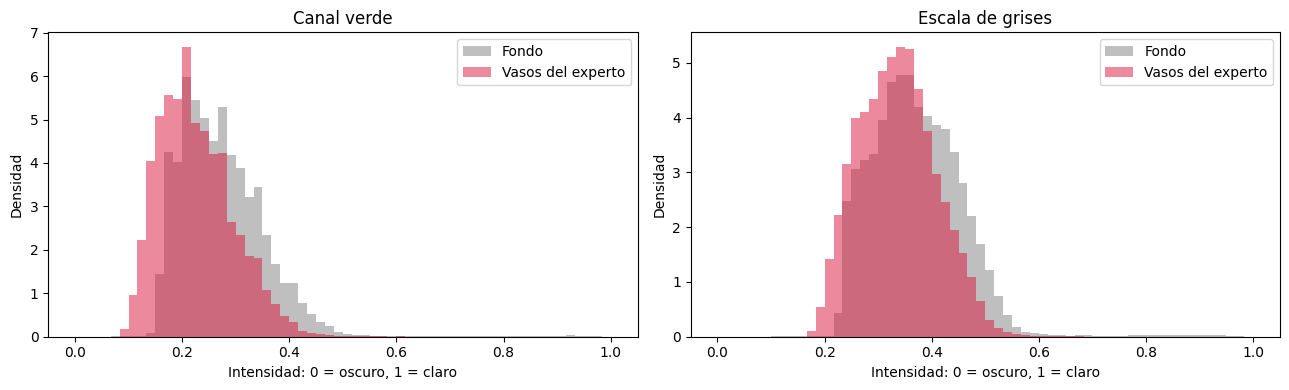

In [ ]:
# Separamos los píxeles según la referencia del experto
zona_vasos = campo & vasos
zona_fondo = campo & ~vasos

mapas_comparar = {
    "Canal verde": verde.astype(np.float32) / 255.0,
    "Escala de grises": gris,
}

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# Mismos intervalos para ambos mapas
intervalos = np.linspace(0, 1, 61)

for eje, (nombre, mapa) in zip(ax, mapas_comparar.items()):
    eje.hist(
        mapa[zona_fondo],
        bins=intervalos,
        density=True,
        alpha=0.5,
        color="gray",
        label="Fondo"
    )

    eje.hist(
        mapa[zona_vasos],
        bins=intervalos,
        density=True,
        alpha=0.5,
        color="crimson",
        label="Vasos del experto"
    )

    eje.set_title(nombre)
    eje.set_xlabel("Intensidad: 0 = oscuro, 1 = claro")
    eje.set_ylabel("Densidad")
    eje.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata

def auc_vasos_oscuros(mapa, referencia, region):
    """AUC considerando que una intensidad menor indica vaso."""

    # Evaluamos solamente dentro del campo de visión
    etiquetas = referencia[region].astype(bool)

    # Cambiamos el signo: más oscuro pasa a tener mayor puntuación
    puntuaciones = -mapa[region].astype(np.float64)

    n_vasos = int(etiquetas.sum())
    n_fondo = int((~etiquetas).sum())

    if n_vasos == 0 or n_fondo == 0:
        raise ValueError("La región debe contener vasos y fondo.")

    # Ordenamos las puntuaciones; los empates reciben rango promedio
    rangos = rankdata(puntuaciones, method="average")

    suma_rangos_vasos = rangos[etiquetas].sum()

    auc = (
        suma_rangos_vasos - n_vasos * (n_vasos + 1) / 2
    ) / (n_vasos * n_fondo)

    return float(auc)


resultados_auc = pd.DataFrame([
    {
        "Imagen": image_id,
        "Mapa": "Canal verde",
        "AUC": auc_vasos_oscuros(verde, vasos, campo)
    },
    {
        "Imagen": image_id,
        "Mapa": "Escala de grises",
        "AUC": auc_vasos_oscuros(gris, vasos, campo)
    }
])

display(resultados_auc.round(4))

,Imagen,Mapa,AUC
0,01_h,Canal verde,0.6787
1,01_h,Escala de grises,0.6187


In [ ]:
from skimage.color import rgb2gray, rgb2lab

# Calculamos los mapas desde la fotografía original
rgb_float = rgb.astype(np.float32) / 255.0
lab = rgb2lab(rgb_float)

mapas = {
    "Rojo": rgb_float[:, :, 0],
    "Verde": rgb_float[:, :, 1],
    "Azul": rgb_float[:, :, 2],
    "Escala de grises": rgb2gray(rgb_float),
    "Lab L*": lab[:, :, 0],
    "Lab a*": lab[:, :, 1],
    "Lab b*": lab[:, :, 2],
}

filas = []

for nombre, mapa in mapas.items():
    auc_oscuros = auc_vasos_oscuros(mapa, vasos, campo)

    filas.append({
        "Imagen": image_id,
        "Mapa": nombre,
        "AUC vasos oscuros": auc_oscuros,
        "AUC vasos claros": 1.0 - auc_oscuros
    })

tabla_mapas = pd.DataFrame(filas)

display(tabla_mapas.round(4))

,Imagen,Mapa,AUC vasos oscuros,AUC vasos claros
0,01_h,Rojo,0.5005,0.4995
1,01_h,Verde,0.6787,0.3213
2,01_h,Azul,0.5273,0.4727
3,01_h,Escala de grises,0.6187,0.3813
4,01_h,Lab L*,0.5600,0.4400
5,01_h,Lab a*,0.3225,0.6775
6,01_h,Lab b*,0.5626,0.4374


In [ ]:
from src.fov import detect_fov_robust

# Detectamos la zona de retina sin usar las máscaras del experto
campo_auto = detect_fov_robust(rgb)

# Cada fila contiene el rojo, verde y azul de un píxel de retina
pixeles = rgb_float[campo_auto]

# Calculamos el promedio y cómo varían juntos los canales
media_rgb = pixeles.mean(axis=0, dtype=np.float64)
covarianza = np.cov(pixeles, rowvar=False)

# Obtenemos las tres direcciones principales
valores, vectores = np.linalg.eigh(covarianza)

# Ordenamos desde la mayor variación hasta la menor
orden = np.argsort(valores)[::-1]
valores = valores[orden]
vectores = vectores[:, orden]

# Fijamos un signo reproducible, sin consultar los vasos
for j in range(3):
    posicion = np.argmax(np.abs(vectores[:, j]))
    if vectores[posicion, j] < 0:
        vectores[:, j] *= -1

# Proyectamos la imagen sobre cada dirección
mapas_pca = {}

for j in range(3):
    direccion = vectores[:, j].astype(np.float32)

    mapas_pca[f"PC{j + 1}"] = (
        rgb_float @ direccion - float(media_rgb @ direccion)
    )

# Liberamos la copia de los píxeles usada para el cálculo
del pixeles

print("Variación explicada por cada componente:")
for nombre, porcentaje in zip(
    mapas_pca, 100 * valores / valores.sum()
):
    print(f"{nombre}: {porcentaje:.2f}%")

Variación explicada por cada componente:
PC1: 85.20%
PC2: 13.84%
PC3: 0.96%


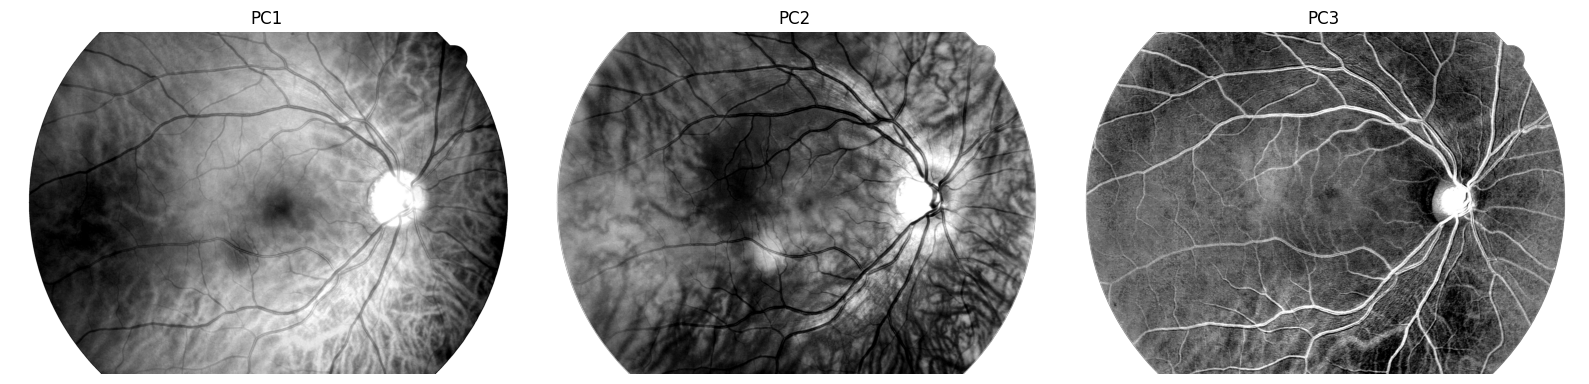

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

for eje, (nombre, mapa) in zip(ax, mapas_pca.items()):
    minimo, maximo = np.percentile(mapa[campo_auto], [1, 99])
    visible = np.ma.masked_where(~campo_auto, mapa)

    eje.imshow(
        visible,
        cmap="gray",
        vmin=minimo,
        vmax=maximo
    )
    eje.set_title(nombre)
    eje.set_facecolor("black")
    eje.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
filas_pca = []

for nombre, mapa in mapas_pca.items():
    auc_oscuros = auc_vasos_oscuros(mapa, vasos, campo)

    filas_pca.append({
        "Imagen": image_id,
        "Mapa": nombre,
        "AUC vasos oscuros": auc_oscuros,
        "AUC vasos claros": 1.0 - auc_oscuros
    })

tabla_pca = pd.DataFrame(filas_pca)

# Reunimos las siete representaciones anteriores y las tres de PCA
tabla_completa = pd.concat(
    [tabla_mapas, tabla_pca],
    ignore_index=True
)

display(tabla_completa.round(4))

,Imagen,Mapa,AUC vasos oscuros,AUC vasos claros
0,01_h,Rojo,0.5005,0.4995
1,01_h,Verde,0.6787,0.3213
2,01_h,Azul,0.5273,0.4727
3,01_h,Escala de grises,0.6187,0.3813
4,01_h,Lab L*,0.5600,0.4400
5,01_h,Lab a*,0.3225,0.6775
6,01_h,Lab b*,0.5626,0.4374
7,01_h,PC1,0.5495,0.4505
8,01_h,PC2,0.6860,0.3140
9,01_h,PC3,0.1586,0.8414


In [ ]:
import numpy as np
import pandas as pd

from skimage.color import rgb2gray, rgb2lab
from src.data import dev_ids, load_image, load_vessels, load_fov
from src.fov import detect_fov_robust
from src.config import RESULTS_DIR


def crear_mapas(rgb):
    """Crea los diez mapas usando solamente la fotografía."""

    imagen = rgb.astype(np.float32) / 255.0
    lab = rgb2lab(imagen)

    mapas = {
        "Rojo": imagen[:, :, 0],
        "Verde": imagen[:, :, 1],
        "Azul": imagen[:, :, 2],
        "Escala de grises": rgb2gray(imagen),
        "Lab L*": lab[:, :, 0],
        "Lab a*": lab[:, :, 1],
        "Lab b*": lab[:, :, 2],
    }

    # PCA calculada por imagen dentro de la retina detectada
    region_auto = detect_fov_robust(rgb)
    pixeles = imagen[region_auto]

    media = pixeles.mean(axis=0, dtype=np.float64)
    covarianza = np.cov(pixeles, rowvar=False)
    del pixeles

    valores, vectores = np.linalg.eigh(covarianza)
    orden = np.argsort(valores)[::-1]
    vectores = vectores[:, orden]

    for j in range(3):
        # Misma regla de signo que usamos anteriormente
        posicion = np.argmax(np.abs(vectores[:, j]))

        if vectores[posicion, j] < 0:
            vectores[:, j] *= -1

        direccion = vectores[:, j].astype(np.float32)

        mapas[f"PC{j + 1}"] = (
            imagen @ direccion - float(media @ direccion)
        )

    return mapas


print("Función lista.")

Función lista.


In [ ]:
ids_desarrollo = dev_ids()

assert len(ids_desarrollo) == 30, (
    "Revisar la partición: se esperaban 30 imágenes de desarrollo."
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
archivo_resultados = RESULTS_DIR / "02_auc_mapas_original.csv"

filas_desarrollo = []

for numero, identificador in enumerate(ids_desarrollo, start=1):

    foto = load_image(identificador)
    referencia = load_vessels(identificador)
    region = load_fov(identificador)

    mapas_imagen = crear_mapas(foto)

    for nombre, mapa in mapas_imagen.items():

        auc_oscuros = auc_vasos_oscuros(
            mapa,
            referencia,
            region
        )

        filas_desarrollo.append({
            "Imagen": identificador,
            "Mapa": nombre,
            "AUC vasos oscuros": auc_oscuros,
            "AUC vasos claros": 1.0 - auc_oscuros
        })

    # Guardamos el avance después de cada imagen
    auc_desarrollo = pd.DataFrame(filas_desarrollo)
    auc_desarrollo.to_csv(archivo_resultados, index=False)

    print(
        f"{numero}/{len(ids_desarrollo)} terminada: "
        f"{identificador}",
        flush=True
    )

    # Liberamos los mapas antes de cargar la siguiente fotografía
    del mapas_imagen, mapa, foto, referencia, region

print("\nComparación terminada.")
print("Filas calculadas:", len(auc_desarrollo))

display(auc_desarrollo.head(10).round(4))

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g

Comparación terminada.
Filas calculadas: 300


,Imagen,Mapa,AUC vasos oscuros,AUC vasos claros
0,01_h,Rojo,0.5005,0.4995
1,01_h,Verde,0.6787,0.3213
2,01_h,Azul,0.5273,0.4727
3,01_h,Escala de grises,0.6187,0.3813
4,01_h,Lab L*,0.5600,0.4400
5,01_h,Lab a*,0.3225,0.6775
6,01_h,Lab b*,0.5626,0.4374
7,01_h,PC1,0.5495,0.4505
8,01_h,PC2,0.6860,0.3140
9,01_h,PC3,0.1586,0.8414


In [ ]:
columnas_auc = ["AUC vasos oscuros", "AUC vasos claros"]

# Media por mapa, dando el mismo peso a cada imagen
medias = auc_desarrollo.groupby("Mapa")[columnas_auc].mean()

# Elegimos un único sentido para cada mapa
sentidos = medias.idxmax(axis=1)

filas_resumen = []

for nombre, grupo in auc_desarrollo.groupby("Mapa"):

    columna = sentidos.loc[nombre]
    valores = grupo[columna]

    filas_resumen.append({
        "Mapa": nombre,
        "Sentido elegido": (
            "Oscuros" if columna == "AUC vasos oscuros" else "Claros"
        ),
        "Imágenes": len(grupo),
        "AUC media": valores.mean(),
        "Desvío entre imágenes": valores.std(),
        "AUC mínima": valores.min(),
        "AUC máxima": valores.max()
    })

resumen_auc = (
    pd.DataFrame(filas_resumen)
    .sort_values("AUC media", ascending=False)
    .reset_index(drop=True)
)

display(resumen_auc.round(4))

,Mapa,Sentido elegido,Imágenes,AUC media,Desvío entre imágenes,AUC mínima,AUC máxima
0,PC3,Claros,30,0.8115,0.0388,0.7160,0.8625
1,PC2,Oscuros,30,0.7582,0.1182,0.1945,0.8603
2,Lab a*,Claros,30,0.6949,0.0580,0.6118,0.8447
3,Verde,Oscuros,30,0.6894,0.0396,0.6118,0.7875
4,Escala de grises,Oscuros,30,0.6214,0.0370,0.5604,0.7099
5,Lab b*,Oscuros,30,0.5785,0.0516,0.4573,0.6619
6,Lab L*,Oscuros,30,0.5551,0.0327,0.5108,0.6243
7,PC1,Oscuros,30,0.5368,0.0288,0.4820,0.5922
8,Azul,Claros,30,0.5078,0.0425,0.4133,0.5920
9,Rojo,Claros,30,0.5041,0.0214,0.4617,0.5594


In [ ]:
display(
    auc_desarrollo.loc[
        auc_desarrollo["Mapa"] == "PC2",
        ["Imagen", "AUC vasos oscuros", "AUC vasos claros"]
    ]
    .sort_values("AUC vasos oscuros")
    .head(5)
    .round(4)
)

,Imagen,AUC vasos oscuros,AUC vasos claros
148,08_dr,0.1945,0.8055
138,06_dr,0.6829,0.3171
8,01_h,0.6860,0.3140
208,03_g,0.6904,0.3096
28,03_h,0.7093,0.2907


In [ ]:
from src.data import load_split

# Una fila por imagen y una columna por mapa
auc_oscuros = auc_desarrollo.pivot(
    index="Imagen",
    columns="Mapa",
    values="AUC vasos oscuros"
)

assert auc_oscuros.shape == (30, 10)
assert not auc_oscuros.isna().any().any()

# Conservamos el sentido que ya elegimos para cada mapa
sentidos_fijos = resumen_auc.set_index("Mapa")["Sentido elegido"]

auc_orientadas = auc_oscuros.copy()

for nombre in auc_orientadas.columns:
    if sentidos_fijos.loc[nombre] == "Claros":
        auc_orientadas[nombre] = 1.0 - auc_oscuros[nombre]

# Asociamos cada imagen con la persona indicada en la partición
particion = load_split().set_index("image")
personas = particion.loc[auc_orientadas.index, "person"]

assert personas.notna().all()

# Agrupamos las AUC por persona
datos = auc_orientadas.to_numpy()
nombres = auc_orientadas.columns

personas_unicas, grupos = np.unique(
    personas.to_numpy(),
    return_inverse=True
)

n_personas = len(personas_unicas)

sumas = np.zeros((n_personas, datos.shape[1]))
np.add.at(sumas, grupos, datos)

cantidades = np.bincount(grupos)

# Elegimos como referencia el mapa con mayor AUC media
medias = auc_orientadas.mean()
mejor = medias.idxmax()
posicion_mejor = nombres.get_loc(mejor)

# Remuestreo de personas: sus ojos siempre viajan juntos
rng = np.random.default_rng(2026)

sorteos = rng.integers(
    0, n_personas,
    size=(2000, n_personas)
)

medias_remuestreadas = (
    sumas[sorteos].sum(axis=1)
    / cantidades[sorteos].sum(axis=1)[:, None]
)

# Diferencias apareadas respecto del mejor mapa
diferencias = (
    medias_remuestreadas
    - medias_remuestreadas[:, [posicion_mejor]]
)

inferior, superior = np.percentile(
    diferencias,
    [2.5, 97.5],
    axis=0
)

comparacion = pd.DataFrame({
    "Mapa": nombres,
    "AUC media": medias.to_numpy(),
    "Diferencia respecto del mejor": (
        medias - medias.loc[mejor]
    ).to_numpy(),
    "Límite inferior 95%": inferior,
    "Límite superior 95%": superior
})

# Margen de no inferioridad establecido en el plan
comparacion["Cumple margen de 0,02"] = inferior >= -0.02

comparacion = comparacion.sort_values(
    "AUC media",
    ascending=False
).reset_index(drop=True)

print("Mapa de referencia:", mejor)
print("Personas de desarrollo:", n_personas)

display(comparacion.round(4))

Mapa de referencia: PC3
Personas de desarrollo: 18


,Mapa,AUC media,Diferencia respecto del mejor,Límite inferior 95%,Límite superior 95%,"Cumple margen de 0,02"
0,PC3,0.8115,0.0000,0.0000,0.0000,True
1,PC2,0.7582,-0.0533,-0.1065,-0.0116,False
2,Lab a*,0.6949,-0.1166,-0.1413,-0.0858,False
3,Verde,0.6894,-0.1221,-0.1376,-0.1034,False
4,Escala de grises,0.6214,-0.1901,-0.2049,-0.1732,False
5,Lab b*,0.5785,-0.2330,-0.2576,-0.2072,False
6,Lab L*,0.5551,-0.2564,-0.2718,-0.2381,False
7,PC1,0.5368,-0.2747,-0.2897,-0.2576,False
8,Azul,0.5078,-0.3037,-0.3254,-0.2791,False
9,Rojo,0.5041,-0.3074,-0.3263,-0.2872,False
